In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train_data_df = pd.read_csv("../data/train.csv")
test_data_df = pd.read_csv("../data/test.csv")

In [3]:
train_data_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
train_data_df['SalePrice'].min()

np.int64(34900)

In [5]:
test_data_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal


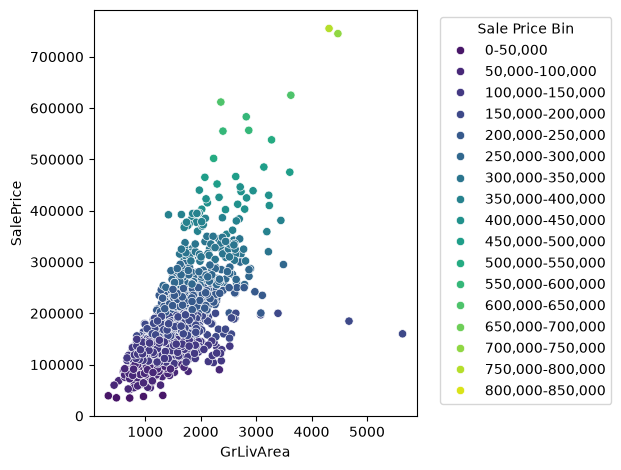

In [8]:
# make bin labels for housing prices every $50,000
sale_price_bins = [
    f'{i:,}-{i+50_000:,}'
    for i in range(0, 850_000, 50_000)
]

# create new column and map price to correct bin
train_data_df['SalePriceBin'] = pd.cut(
    train_data_df['SalePrice'],
    bins=list(range(0, 850001, 50000)),
    labels=sale_price_bins,
    include_lowest=True
)

# plot the living area comapred to price and use the pricing bins as hue
sns.scatterplot(
    data=train_data_df,
    x='GrLivArea',
    y='SalePrice',
    hue='SalePriceBin',
    palette='viridis'
)

plt.legend(title='Sale Price Bin', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

It appears that there is a positive correlation between the amount of living area and the price.

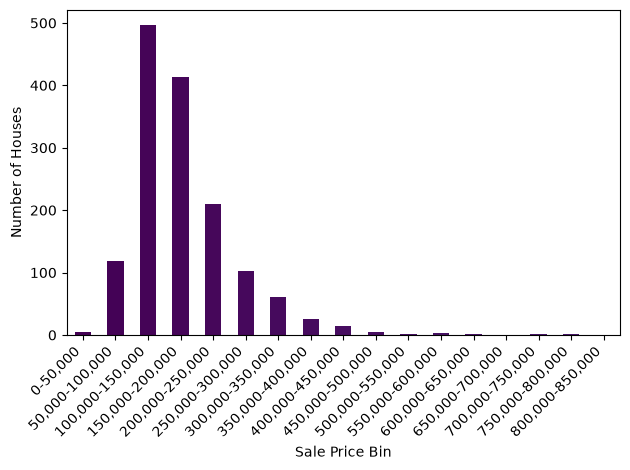

In [9]:
train_data_df['SalePriceBin'].value_counts(sort=False).plot(kind='bar', color=plt.cm.viridis(
    range(len(sale_price_bins))
))
plt.xticks(rotation=45, ha='right')
plt.xlabel('Sale Price Bin')
plt.ylabel('Number of Houses')
plt.tight_layout()
plt.show()

Most houses fell within $100,000 and $250,000.